In [66]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.metrics import accuracy_score
import scipy.stats as stats 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer



In [67]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [68]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [69]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [70]:
df['Age'].fillna(df['Age'].mean(),inplace=True)

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_7992\694922604.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(),inplace=True)


In [71]:
x = df[['Age','Fare']]
y = df['Survived']

In [72]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_7992\2129554055.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Age'])


((array([-3.09833772e+00, -2.82529557e+00, -2.67239243e+00, -2.56428702e+00,
         -2.47977990e+00, -2.40996845e+00, -2.35023723e+00, -2.29787334e+00,
         -2.25114194e+00, -2.20886405e+00, -2.17020067e+00, -2.13453273e+00,
         -2.10138998e+00, -2.07040647e+00, -2.04129166e+00, -2.01381086e+00,
         -1.98777170e+00, -1.96301446e+00, -1.93940499e+00, -1.91682952e+00,
         -1.89519069e+00, -1.87440451e+00, -1.85439799e+00, -1.83510731e+00,
         -1.81647630e+00, -1.79845528e+00, -1.78100007e+00, -1.76407122e+00,
         -1.74763334e+00, -1.73165455e+00, -1.71610603e+00, -1.70096166e+00,
         -1.68619765e+00, -1.67179230e+00, -1.65772574e+00, -1.64397975e+00,
         -1.63053756e+00, -1.61738369e+00, -1.60450386e+00, -1.59188484e+00,
         -1.57951433e+00, -1.56738092e+00, -1.55547396e+00, -1.54378354e+00,
         -1.53230037e+00, -1.52101577e+00, -1.50992160e+00, -1.49901023e+00,
         -1.48827446e+00, -1.47770753e+00, -1.46730308e+00, -1.45705508e+00,

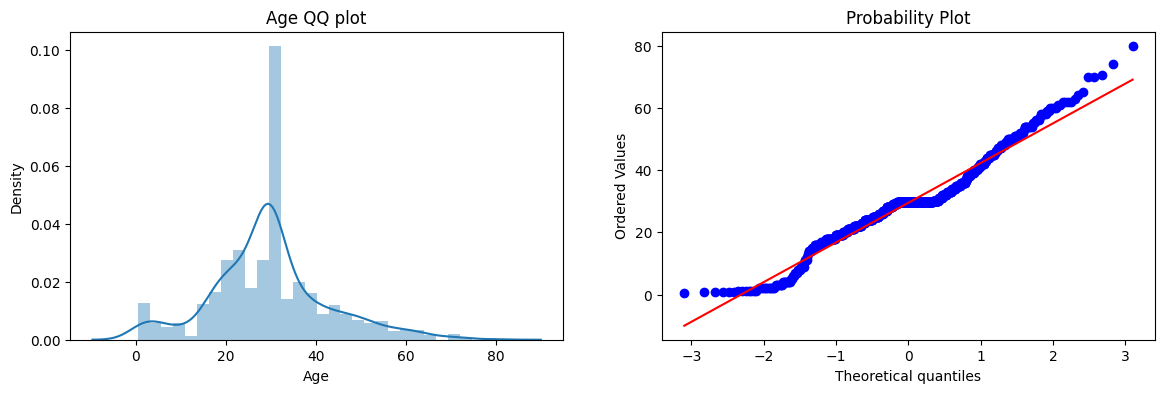

In [73]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.distplot(df['Age'])
plt.title('Age QQ plot')
plt.subplot(122)
stats.probplot(x_train['Age'],dist='norm',plot=plt)

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_7992\1397617015.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Fare'])


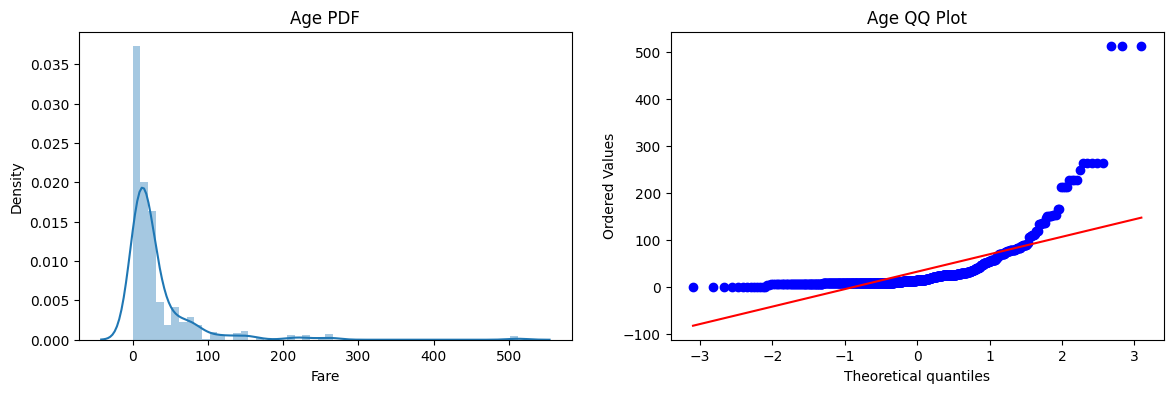

In [74]:
plt.figure(figsize=(14, 4))
plt.subplot(121)
sns.distplot(x_train['Fare'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['Fare'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

# the fare column is not normaly distributed and is right skewed

In [75]:
clf1 = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [81]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)
y_pred1 = clf1.predict(x_test)
y_pred2 = clf2.predict(x_test)

print("Acuracy Score of LG ",accuracy_score(y_test,y_pred1))
print("Acuracy Score of DT ",accuracy_score(y_test,y_pred2))

Acuracy Score of LG  0.6480446927374302
Acuracy Score of DT  0.6815642458100558


# Now applying the tanformation and then try to check wether the accuracy increases or not

In [63]:
trf = FunctionTransformer(func=np.log1p)

In [65]:
X_train_transformed = trf.fit_transform(x_train)
X_test_transformed = trf.transform(x_test)


In [82]:
clf1= LogisticRegression()
clf2 = DecisionTreeClassifier()

clf1.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)

y_pred1 = clf1.predict(x_test)
y_pred2 = clf2.predict(x_test)

print("Accuracy score LR  ",accuracy_score(y_test,y_pred1))
print("Accuracy score DT  ",accuracy_score(y_test,y_pred2))



Accuracy score LR   0.7374301675977654
Accuracy score DT   0.5921787709497207


# we can see that applying Log transformer on a right skewed data we see improvement in the accuracy